In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv("Vehicle_Collision.csv")
df.head()

,UNIQUE_ID,COLLISION_ID,CRASH_DATE,CRASH_TIME,PERSON_ID,PERSON_TYPE,PERSON_INJURY,VEHICLE_ID,PERSON_AGE,EJECTION,...,BODILY_INJURY,POSITION_IN_VEHICLE,SAFETY_EQUIPMENT,PED_LOCATION,PED_ACTION,COMPLAINT,PED_ROLE,CONTRIBUTING_FACTOR_1,CONTRIBUTING_FACTOR_2,PERSON_SEX
0,10253606,4230743.0,10/24/2019,19:15,84bcb3a7-d201-4c61-9e30-fe29268c1074,Occupant,Injured,19143343.0,27.0,Not Ejected,...,Back,Driver,Lap Belt & Harness,NaN,NaN,Complaint of Pain or Nausea,Driver,NaN,NaN,M
1,10248708,4229547.0,10/26/2019,1:15,a8904763-2870-42f3-865c-b53d8e5156e2,Pedestrian,Injured,NaN,24.0,NaN,...,Shoulder - Upper Arm,NaN,NaN,Pedestrian/Bicyclist/Other Pedestrian at Inter...,Crossing With Signal,None Visible,Pedestrian,Unspecified,Unspecified,F
2,10254556,4230715.0,10/26/2019,8:50,1a085543-ae9d-4a69-8cd0-fb7b33380a8b,Bicyclist,Injured,19143832.0,42.0,Not Ejected,...,Knee-Lower Leg Foot,Driver,Unknown,NaN,NaN,None Visible,Driver,NaN,NaN,M
3,10250834,4230376.0,10/26/2019,19:40,f58fc41f-497e-4f30-bf49-a9a80adec8b2,Bicyclist,Injured,19141949.0,36.0,Not Ejected,...,Back,Driver,NaN,NaN,NaN,Internal,Driver,NaN,NaN,M
4,10252474,4229773.0,10/26/2019,16:50,4bf13d12-8d7a-4cb0-997f-dd6a8b1adca6,Occupant,Injured,19142773.0,50.0,Not Ejected,...,Head,"Front passenger, if two or more persons, inclu...",Lap Belt & Harness,NaN,NaN,Complaint of Pain or Nausea,Passenger,NaN,NaN,F


In [4]:
df = df.dropna(subset=['PERSON_INJURY'])

In [5]:
drop_cols = [
    'UNIQUE_ID',
    'COLLISION_ID',
    'PERSON_ID',
    'VEHICLE_ID'
]

df = df.drop(columns=drop_cols)

In [6]:
X = df.drop('PERSON_INJURY', axis=1)

y = df['PERSON_INJURY'].map({
    'Injured': 0,
    'Killed': 1
})

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [8]:
num_cols = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

cat_cols = X_train.select_dtypes(
    include='object'
).columns.tolist()

In [9]:
for col in cat_cols:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

In [10]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

In [11]:
print(X_train.shape)
print(X_test.shape)

print("Numerical Columns:", len(num_cols))
print("Categorical Columns:", len(cat_cols))

(184524, 16)
(46132, 16)
Numerical Columns: 1
Categorical Columns: 15


In [19]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

In [20]:
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        class_weight='balanced',
        random_state=42
    ))
])

In [21]:
param_grid = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [10, 20, 30, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

In [22]:
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=3,
    cv=3,
    scoring='f1',
    random_state=42,
    n_jobs=-1
)

In [23]:
random_search.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'classifier__max_depth': [10, 20, ...], 'classifier__min_samples_leaf': [1, 2, ...], 'classifier__min_samples_split': [2, 5, ...], 'classifier__n_estimators': [100, 200, ...]}"
,n_iter,3
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [24]:
best_model = random_search.best_estimator_

In [25]:
y_pred = best_model.predict(X_test)

In [26]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.90      0.95     45927
           1       0.03      0.68      0.06       205

    accuracy                           0.90     46132
   macro avg       0.51      0.79      0.50     46132
weighted avg       0.99      0.90      0.94     46132



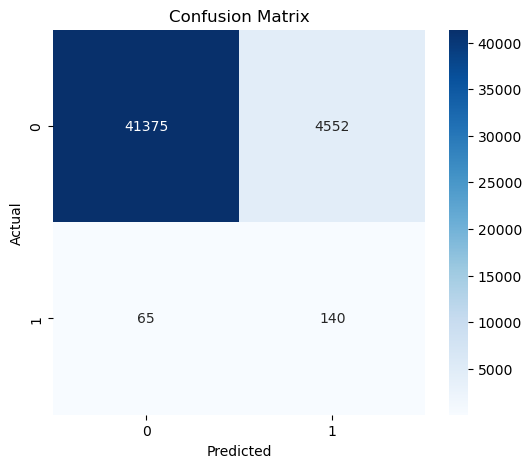

In [27]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

### Confusion Matrix Analysis

- True Positives (Killed correctly predicted)
- True Negatives (Injured correctly predicted)
- False Positives
- False Negatives

Special attention should be given to False Negatives because
predicting a fatal accident as non-fatal is a more serious error.

In [28]:
results = X_test.copy()
results['Actual'] = y_test.values
results['Predicted'] = y_pred

In [29]:
false_positive = results[
    (results['Actual'] == 0) &
    (results['Predicted'] == 1)
]
false_positive.head()

,CRASH_DATE,CRASH_TIME,PERSON_TYPE,PERSON_AGE,EJECTION,EMOTIONAL_STATUS,BODILY_INJURY,POSITION_IN_VEHICLE,SAFETY_EQUIPMENT,PED_LOCATION,PED_ACTION,COMPLAINT,PED_ROLE,CONTRIBUTING_FACTOR_1,CONTRIBUTING_FACTOR_2,PERSON_SEX,Actual,Predicted
209783,12/23/2013,12:40,Pedestrian,32.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0,1
26912,07/04/2012,6:30,Pedestrian,30.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0,1
224207,10/13/2017,20:09,Pedestrian,34.0,nan,Conscious,Head,nan,nan,Pedestrian/Bicyclist/Other Pedestrian Not at I...,Other Actions in Roadway,Complaint of Pain,Pedestrian,Pedestrian/Bicyclist/Other Pedestrian Error/Co...,Pedestrian/Bicyclist/Other Pedestrian Error/Co...,M,0,1
13598,12/02/2014,13:30,Pedestrian,17.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0,1
48421,02/22/2013,14:10,Pedestrian,52.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0,1


In [30]:
print("False Positives :", len(false_positive))

False Positives : 4552


In [31]:
false_negative = results[
    (results['Actual'] == 1) &
    (results['Predicted'] == 0)
]
false_negative.head()

,CRASH_DATE,CRASH_TIME,PERSON_TYPE,PERSON_AGE,EJECTION,EMOTIONAL_STATUS,BODILY_INJURY,POSITION_IN_VEHICLE,SAFETY_EQUIPMENT,PED_LOCATION,PED_ACTION,COMPLAINT,PED_ROLE,CONTRIBUTING_FACTOR_1,CONTRIBUTING_FACTOR_2,PERSON_SEX,Actual,Predicted
55298,12/03/2013,8:45,Occupant,49.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,1,0
166836,04/04/2014,22:35,Occupant,19.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,1,0
210523,09/23/2015,19:05,Occupant,38.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,1,0
184450,03/20/2013,16:04,Occupant,23.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,1,0
117290,05/24/2015,5:40,Occupant,24.0,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,1,0


In [32]:
print("False Negatives :", len(false_negative))

False Negatives : 65


### Error Analysis

False Negative cases are more critical because
the model failed to identify fatal injury cases.

These records should be inspected to understand
which factors contribute to incorrect predictions.

In [33]:
rf_model = best_model.named_steps['classifier']

In [34]:
feature_names = best_model.named_steps[
    'preprocessor'
].get_feature_names_out()

In [35]:
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

In [36]:
top15 = importance_df.head(15)

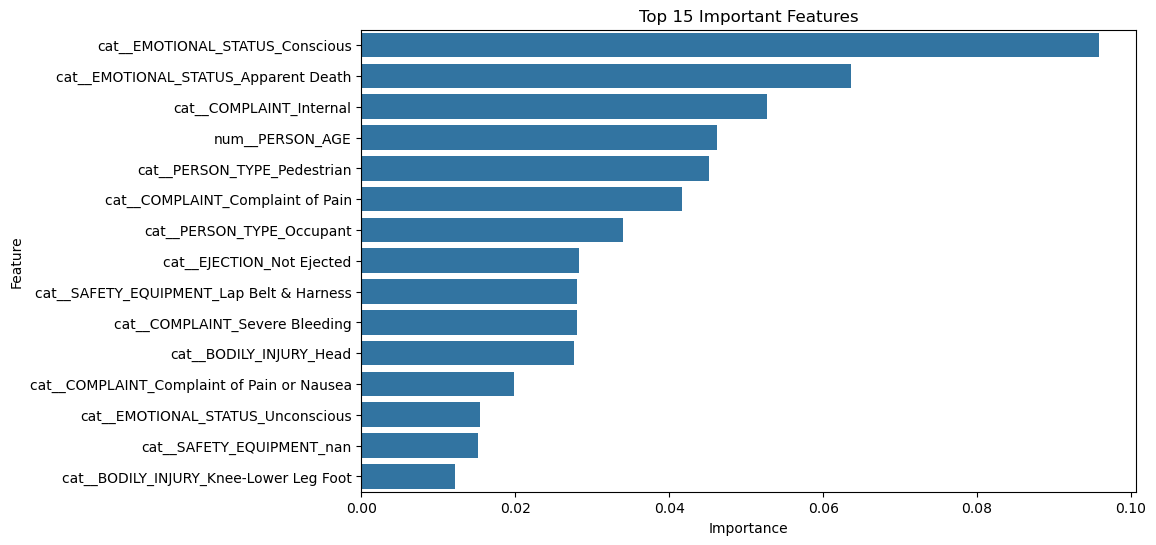

In [37]:
plt.figure(figsize=(10,6))
sns.barplot(
    data=top15,
    x='Importance',
    y='Feature'
)
plt.title("Top 15 Important Features")
plt.show()

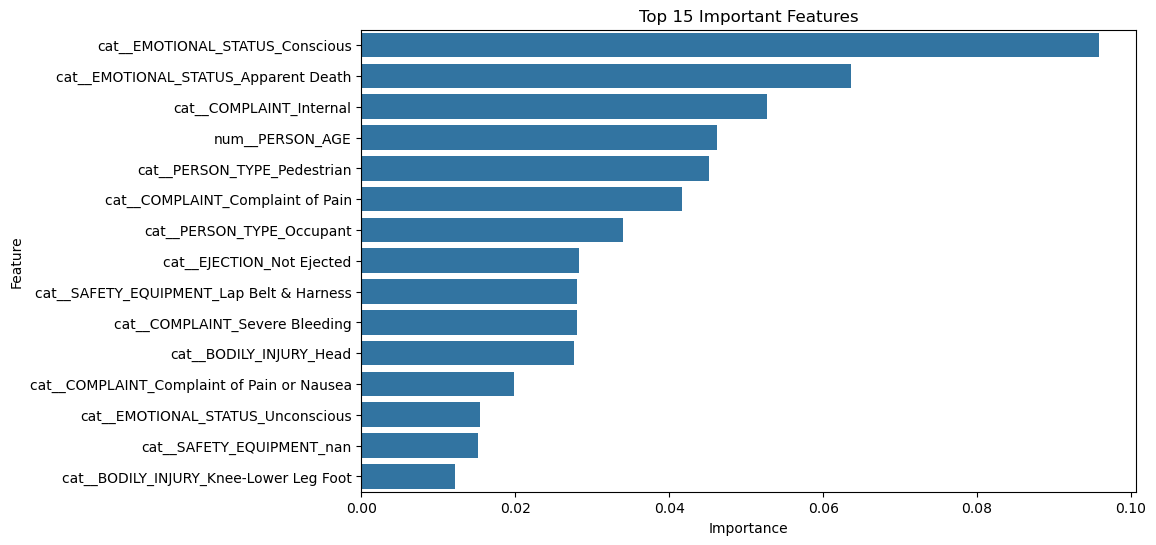

In [38]:
plt.figure(figsize=(10,6))
sns.barplot(
    data=top15,
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Important Features")
plt.show()

In [39]:
y_prob = best_model.predict_proba(X_test)[:,1]

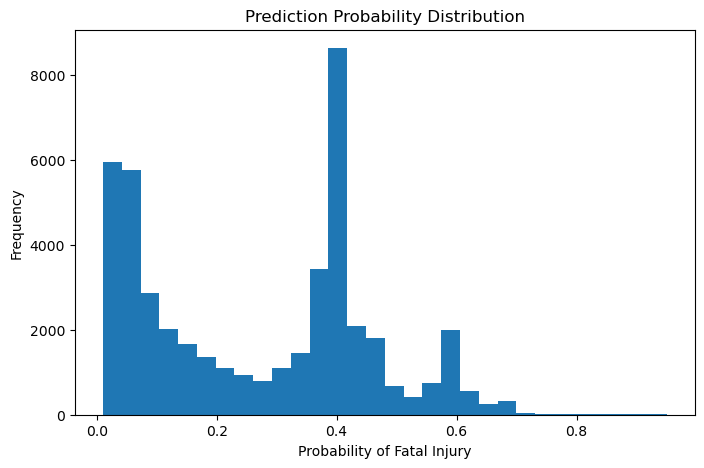

In [40]:
plt.figure(figsize=(8,5))
plt.hist(
    y_prob,
    bins=30
)
plt.title("Prediction Probability Distribution")
plt.xlabel("Probability of Fatal Injury")
plt.ylabel("Frequency")
plt.show()

### Probability Analysis

The distribution of prediction probabilities helps
understand model confidence and threshold behavior.

## Error Analysis and Explainability Summary

- Evaluated model using confusion matrix.
- Analyzed false positive and false negative cases.
- Identified most important predictive features.
- Examined prediction probability distribution.
- Improved interpretability of the Random Forest model.